<a href="https://colab.research.google.com/github/yhkim8065-dev/inchang/blob/main/inchang_yolo1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

피카츄 만들기

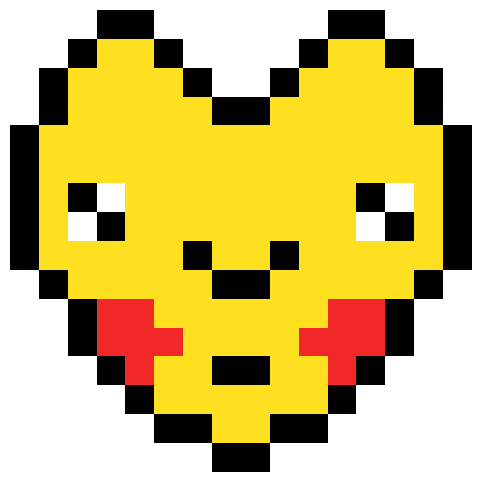

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# 피카츄 픽셀 아트 데이터 정의 (모든 행의 길이를 16개로 일치시킴)
pikachu_grid = [
    [0,0,0,2,2,0,0,0,0,0,0,2,2,0,0,0],
    [0,0,2,1,1,2,0,0,0,0,2,1,1,2,0,0],
    [0,2,1,1,1,1,2,0,0,2,1,1,1,1,2,0],
    [0,2,1,1,1,1,1,2,2,1,1,1,1,1,2,0],
    [2,1,1,1,1,1,1,1,1,1,1,1,1,1,1,2],
    [2,1,1,1,1,1,1,1,1,1,1,1,1,1,1,2],
    [2,1,2,4,1,1,1,1,1,1,1,1,2,4,1,2],
    [2,1,4,2,1,1,1,1,1,1,1,1,4,2,1,2],
    [2,1,1,1,1,1,2,1,1,2,1,1,1,1,1,2],
    [0,2,1,1,1,1,1,2,2,1,1,1,1,1,2,0],
    [0,0,2,3,3,1,1,1,1,1,1,3,3,2,0,0],
    [0,0,2,3,3,3,1,1,1,1,3,3,3,2,0,0],
    [0,0,0,2,3,1,1,2,2,1,1,3,2,0,0,0],
    [0,0,0,0,2,1,1,1,1,1,1,2,0,0,0,0],
    [0,0,0,0,0,2,2,1,1,2,2,0,0,0,0,0], # 기존 15개에서 16개로 수정
    [0,0,0,0,0,0,0,2,2,0,0,0,0,0,0,0]
]

# 색상 맵 정의
# 0: 흰색 배경, 1: 피카츄 노란색, 2: 검은색 테두리/눈, 3: 볼 빨간색, 4: 눈동자 흰색
colors = np.array([
    [255, 255, 255], # 0: White
    [255, 224, 32],  # 1: Yellow
    [0, 0, 0],       # 2: Black
    [240, 40, 40],   # 3: Red
    [255, 255, 255]  # 4: White
]) / 255.0

# 픽셀 데이터를 RGB 이미지로 변환
img = colors[np.array(pikachu_grid)]

# 그리기
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis('off') # 축 숨기기
plt.show()

좀더 섬세하게 만들어주는 소스코드를 작성해줘!
피카츄 귀를 붙여줘!

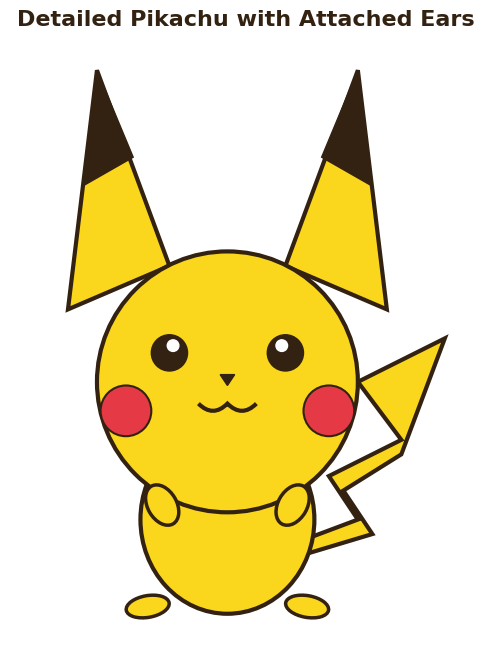

In [4]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.path import Path

fig, ax = plt.subplots(figsize=(8, 8))
ax.set_aspect('equal')

# 배경색 설정 (부드러운 연청색)
ax.set_facecolor('#E6F2FF')

# 1. 귀 그리기 (머리와 부드럽게 이어지도록 위치 조정 및 zorder 상향 조정)
# 귀 노란색 부분
left_ear = patches.Polygon([[1.8, 5.2], [2.2, 8.5], [3.2, 5.8]], closed=True, color='#FAD61D', ec='#332211', lw=3, zorder=2)
right_ear = patches.Polygon([[6.2, 5.2], [5.8, 8.5], [4.8, 5.8]], closed=True, color='#FAD61D', ec='#332211', lw=3, zorder=2)
ax.add_patch(left_ear)
ax.add_patch(right_ear)

# 귀 끝 검은색 부분
left_ear_tip = patches.Polygon([[2.0, 6.9], [2.2, 8.5], [2.7, 7.3]], closed=True, color='#332211', zorder=3)
right_ear_tip = patches.Polygon([[6.0, 6.9], [5.8, 8.5], [5.3, 7.3]], closed=True, color='#332211', zorder=3)
ax.add_patch(left_ear_tip)
ax.add_patch(right_ear_tip)

# 2. 얼굴 및 몸통 바디
# 얼굴 메인 원
face = patches.Circle((4, 4.2), radius=1.8, color='#FAD61D', ec='#332211', lw=3, zorder=2) # zorder를 귀와 자연스럽게 맞춤
# 몸통 타원
body = patches.Ellipse((4, 2.3), width=2.4, height=2.6, color='#FAD61D', ec='#332211', lw=3, zorder=1)
ax.add_patch(face)
ax.add_patch(body)

# 3. 눈동자 (하안 하이라이트 포함)
left_eye = patches.Circle((3.2, 4.6), radius=0.25, color='#332211', zorder=4)
right_eye = patches.Circle((4.8, 4.6), radius=0.25, color='#332211', zorder=4)
left_eye_shine = patches.Circle((3.25, 4.7), radius=0.08, color='white', zorder=5)
right_eye_shine = patches.Circle((4.75, 4.7), radius=0.08, color='white', zorder=5)
ax.add_patch(left_eye)
ax.add_patch(right_eye)
ax.add_patch(left_eye_shine)
ax.add_patch(right_eye_shine)

# 4. 볼터치 (시그니처 빨간 볼)
left_cheek = patches.Circle((2.6, 3.8), radius=0.35, color='#E63946', ec='#332211', lw=1.5, zorder=3)
right_cheek = patches.Circle((5.4, 3.8), radius=0.35, color='#E63946', ec='#332211', lw=1.5, zorder=3)
ax.add_patch(left_cheek)
ax.add_patch(right_cheek)

# 5. 코
nose = patches.Polygon([[3.9, 4.3], [4.1, 4.3], [4.0, 4.15]], closed=True, color='#332211', zorder=4)
ax.add_patch(nose)

# 6. 입 (W자 모양의 귀여운 입 구조)
verts = [
    (3.6, 3.9),
    (3.8, 3.7),
    (4.0, 3.9),
    (4.2, 3.7),
    (4.4, 3.9)
]
codes = [
    Path.MOVETO,
    Path.CURVE3,
    Path.CURVE3,
    Path.CURVE3,
    Path.CURVE3
]
mouth_path = Path(verts, codes)
mouth_patch = patches.PathPatch(mouth_path, facecolor='none', edgecolor='#332211', lw=3, zorder=4)
ax.add_patch(mouth_patch)

# 7. 귀여운 발 (앞발)
left_hand = patches.Ellipse((3.1, 2.5), width=0.4, height=0.6, angle=30, color='#FAD61D', ec='#332211', lw=2.5, zorder=3)
right_hand = patches.Ellipse((4.9, 2.5), width=0.4, height=0.6, angle=-30, color='#FAD61D', ec='#332211', lw=2.5, zorder=3)
ax.add_patch(left_hand)
ax.add_patch(right_hand)

# 뒷발
left_foot = patches.Ellipse((2.9, 1.1), width=0.6, height=0.3, angle=10, color='#FAD61D', ec='#332211', lw=2.5, zorder=1)
right_foot = patches.Ellipse((5.1, 1.1), width=0.6, height=0.3, angle=-10, color='#FAD61D', ec='#332211', lw=2.5, zorder=1)
ax.add_patch(left_foot)
ax.add_patch(right_foot)

# 8. 번개 꼬리
tail_verts = [
    (5.0, 2.0),
    (5.8, 2.3),
    (5.4, 2.9),
    (6.4, 3.4),
    (5.8, 4.2),
    (7.0, 4.8),
    (6.4, 3.2),
    (5.6, 2.7),
    (6.0, 2.1),
    (5.0, 1.8)
]
tail = patches.Polygon(tail_verts, closed=True, color='#FAD61D', ec='#332211', lw=3, zorder=-1)
ax.add_patch(tail)

# 축 범위 설정 및 표시 비활성화
ax.set_xlim(1, 7.5)
ax.set_ylim(0.5, 9)
plt.axis('off')
plt.title("Detailed Pikachu with Attached Ears", fontsize=16, color='#332211', fontweight='bold')
plt.show()